In [ ]:
# Mount Google Drive REMEMBER leave the runtime as Python 3 while running this cell
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load the data
# Replace with your actual path and dataset
file_path <- "/content/drive/My Drive/Colab Notebooks/datasets/Salary Data.csv"

# Read the dataset
data <- read.csv(file_path)

# Check the data
head(data)

# dimensions of the dataset (rows x cols)
dim(data)

# Check data types of variables
sapply(data, class)

,Age,Gender,Education.Level,Job.Title,Years.of.Experience,Salary
,<int>,<chr>,<chr>,<chr>,<dbl>,<int>
1,32,Male,Bachelor's,Software Engineer,5,90000
2,28,Female,Master's,Data Analyst,3,65000
3,45,Male,PhD,Senior Manager,15,150000
4,36,Female,Bachelor's,Sales Associate,7,60000
5,52,Male,Master's,Director,20,200000
6,29,Male,Bachelor's,Marketing Analyst,2,55000


[1] 375   6

Age              Gender     Education.Level           Job.Title 
          "integer"         "character"         "character"         "character" 
Years.of.Experience              Salary 
          "numeric"           "integer"

In [ ]:
# Structure & Summary
# View the structure and summary of the data

cat("=== Structure of Dataset ===\n")
str(data)

cat("\n=== Summary Statistics ===\n")
summary(data)

=== Structure of Dataset ===
'data.frame':	375 obs. of  6 variables:
 $ Age                : int  32 28 45 36 52 29 42 31 26 38 ...
 $ Gender             : chr  "Male" "Female" "Male" "Female" ...
 $ Education.Level    : chr  "Bachelor's" "Master's" "PhD" "Bachelor's" ...
 $ Job.Title          : chr  "Software Engineer" "Data Analyst" "Senior Manager" "Sales Associate" ...
 $ Years.of.Experience: num  5 3 15 7 20 2 12 4 1 10 ...
 $ Salary             : int  90000 65000 150000 60000 200000 55000 120000 80000 45000 110000 ...

=== Summary Statistics ===


      Age           Gender          Education.Level     Job.Title        
 Min.   :23.00   Length:375         Length:375         Length:375        
 1st Qu.:31.00   Class :character   Class :character   Class :character  
 Median :36.00   Mode  :character   Mode  :character   Mode  :character  
 Mean   :37.43                                                           
 3rd Qu.:44.00                                                           
 Max.   :53.00                                                           
 NA's   :2                                                               
 Years.of.Experience     Salary      
 Min.   : 0.00       Min.   :   350  
 1st Qu.: 4.00       1st Qu.: 55000  
 Median : 9.00       Median : 95000  
 Mean   :10.03       Mean   :100577  
 3rd Qu.:15.00       3rd Qu.:140000  
 Max.   :25.00       Max.   :250000  
 NA's   :2           NA's   :2       

In [ ]:
# convert the character attribute(s) to factor (for working with categorical variables in R)
data$Gender <- as.factor(data$Gender)
data$Education.Level <- as.factor(data$Education.Level)
data$Job.Title <- as.factor(data$Job.Title)

names(data)[names(data) == "Gender"] <- "gender"
names(data)[names(data) == "Education.Level"] <- "education"
names(data)[names(data) == "Job.Title"] <- "job"
names(data)[names(data) == "Years.of.Experience"] <- "experience"
names(data)[names(data) == "Age"] <- "age"
names(data)[names(data) == "Salary"] <- "salary"

str(data)

'data.frame':	375 obs. of  6 variables:
 $ age       : int  32 28 45 36 52 29 42 31 26 38 ...
 $ gender    : Factor w/ 3 levels "","Female","Male": 3 2 3 2 3 3 2 3 2 3 ...
 $ education : Factor w/ 4 levels "","Bachelor's",..: 2 3 4 2 3 2 3 2 2 4 ...
 $ job       : Factor w/ 175 levels "","Account Manager",..: 161 19 132 103 24 83 95 106 84 152 ...
 $ experience: num  5 3 15 7 20 2 12 4 1 10 ...
 $ salary    : int  90000 65000 150000 60000 200000 55000 120000 80000 45000 110000 ...


In [ ]:
# Assess the quality of the dataset

# Check for missing values
# Count the missing values in each column
colSums(is.na(data))

age     gender  education        job experience     salary 
         2          0          0          0          2          2

In [ ]:
# display the rows with missing values for an attribute
cat("\n=== missing values age ===\n")
data[!complete.cases(data$age), ]

cat("\n=== missing values experience ===\n")
data[!complete.cases(data$experience), ]

cat("\n=== missing values salary ===\n")
data[!complete.cases(data$salary), ]


=== missing values age ===


,age,gender,education,job,experience,salary
,<int>,<fct>,<fct>,<fct>,<dbl>,<int>
173,NA,,,,NA,NA
261,NA,,,,NA,NA



=== missing values experience ===


,age,gender,education,job,experience,salary
,<int>,<fct>,<fct>,<fct>,<dbl>,<int>
173,NA,,,,NA,NA
261,NA,,,,NA,NA



=== missing values salary ===


,age,gender,education,job,experience,salary
,<int>,<fct>,<fct>,<fct>,<dbl>,<int>
173,NA,,,,NA,NA
261,NA,,,,NA,NA


In [ ]:
# remove rows with missing values - 10 rows in total (save as a new data frame)
data_new <- na.omit(data)

# check the dimension of the data after removing rows
dim(data_new)

[1] 373   6

In [ ]:
# Check for duplicate data
# Count the duplicate data
sum(duplicated(data_new))

# Show the rows with duplicate data
data_new[duplicated(data_new), ]

# NOTE: formatting etc may be causing rows to be returned as duplicates when they are not - if there are no ture duplicates there no further steps need to be taken

# However, there seems to be an unused level 0 - we can remove this so that it is not included in our analysis
# drop unused factor levels (the 0)
data_new$gender <- factor(data_new$gender)
data_new$education <- factor(data_new$education)
data_new$job <- factor(data_new$job)

# Drops any duplicates (if required)
# data_unique <- data_new[!duplicated(data_new), ]

# cat("Rows before:", nrow(data_new), "\nRows after:", nrow(data_unique))

[1] 49

,age,gender,education,job,experience,salary
,<int>,<fct>,<fct>,<fct>,<dbl>,<int>
196,28,Male,Bachelor's,Junior Business Analyst,2.0,40000
251,30,Female,Bachelor's,Junior Marketing Coordinator,2.0,40000
252,38,Male,Master's,Senior IT Consultant,9.0,110000
253,45,Female,PhD,Senior Product Designer,15.0,150000
254,28,Male,Bachelor's,Junior Business Development Associate,2.0,40000
255,35,Female,Bachelor's,Senior Marketing Analyst,8.0,85000
256,44,Male,Bachelor's,Senior Software Engineer,14.0,130000
257,34,Female,Master's,Senior Financial Advisor,6.0,100000
258,35,Male,Bachelor's,Senior Project Coordinator,9.0,95000


# **UNIVARIATE ANALYSIS**

In [ ]:
# Basic statistics UNIVARIATE Analysis
numeric_data <- sapply(data_new, is.numeric)
# Using the numeric data create a table of the summary statistics for mean, median, standard deviation and interquatile range
stats <- data.frame(
  Variable = names(data_new)[numeric_data],
  Mean = sapply(data_new[, numeric_data], mean),
  Median = sapply(data_new[, numeric_data], median),
  SD = sapply(data_new[, numeric_data], sd),
  interquartile = sapply(data_new[, numeric_data], IQR) )
  stats

,Variable,Mean,Median,SD,interquartile
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
age,age,37.43164,36,7.069073,13
experience,experience,10.03083,9,6.557007,11
salary,salary,100577.34584,95000,48240.013482,85000


In [ ]:
# create a frequency table for each species and the proportion of each

cat("\n=== frequency table Gender ===\n")
table(data_new$gender)
prop.table(table(data_new$gender))

cat("\n=== frequency table Education Level ===\n")
table(data_new$education)
prop.table(table(data_new$education))

cat("\n=== frequency table Job Title ===\n")
table(data_new$job)
prop.table(table(data_new$job))


=== frequency table Gender ===



Female   Male 
   179    194 


   Female      Male 
0.4798928 0.5201072 


=== frequency table Education Level ===



Bachelor's   Master's        PhD 
       224         98         51 


Bachelor's   Master's        PhD 
 0.6005362  0.2627346  0.1367292 


=== frequency table Job Title ===



                      Account Manager                            Accountant 
                                    1                                     1 
             Administrative Assistant                      Business Analyst 
                                    2                                     2 
         Business Development Manager         Business Intelligence Analyst 
                                    1                                     1 
                                  CEO                    Chief Data Officer 
                                    1                                     1 
             Chief Technology Officer             Content Marketing Manager 
                                    1                                     1 
                           Copywriter                     Creative Director 
                                    1                                     1 
             Customer Service Manager                  Customer Service Rep


                      Account Manager                            Accountant 
                          0.002680965                           0.002680965 
             Administrative Assistant                      Business Analyst 
                          0.005361930                           0.005361930 
         Business Development Manager         Business Intelligence Analyst 
                          0.002680965                           0.002680965 
                                  CEO                    Chief Data Officer 
                          0.002680965                           0.002680965 
             Chief Technology Officer             Content Marketing Manager 
                          0.002680965                           0.002680965 
                           Copywriter                     Creative Director 
                          0.002680965                           0.002680965 
             Customer Service Manager                  Customer Service Rep

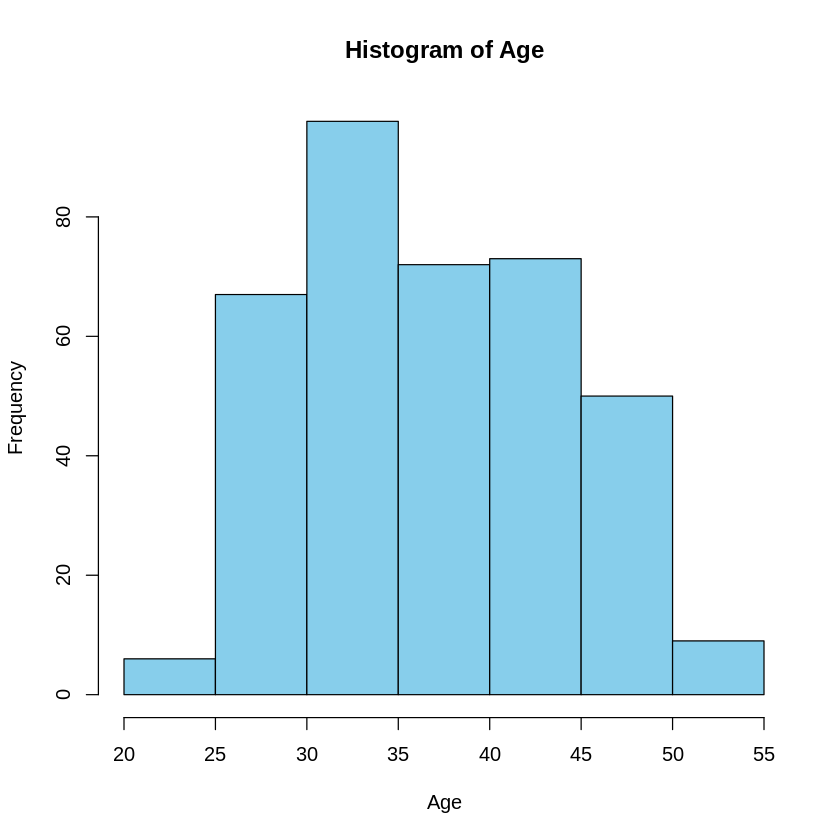

In [ ]:
# Use histograms to view the distribution of each numeric variable

# Histogram - age
hist(data_new$age,
     main = "Histogram of Age",
     xlab = "Age",
     col = "skyblue",
     border = "black")

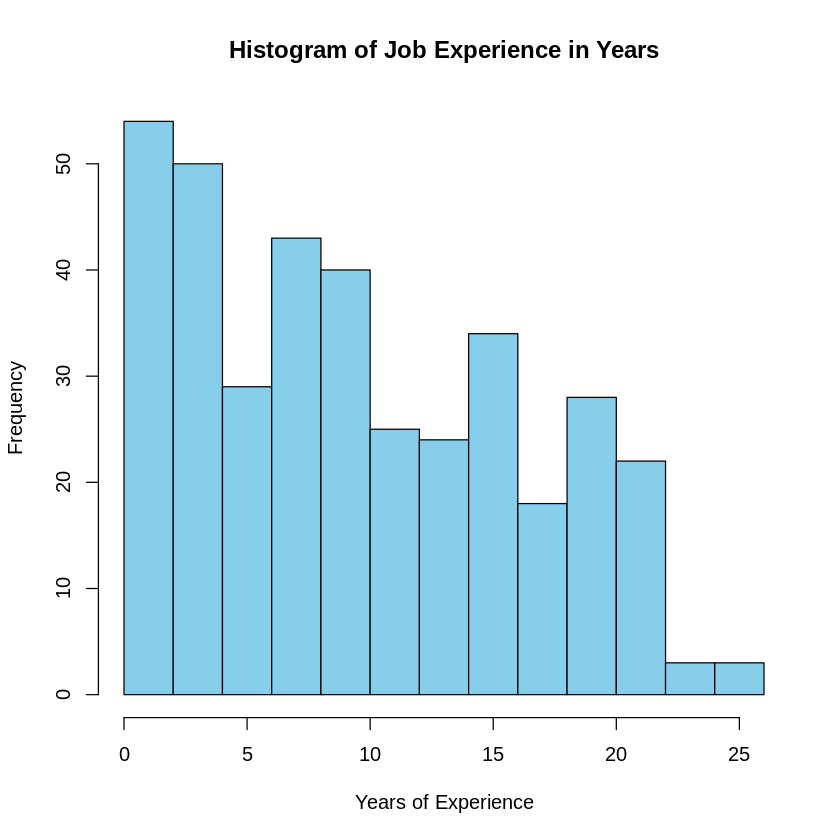

In [ ]:
# Histogram - years of experience
hist(data_new$experience,
     main = "Histogram of Job Experience in Years",
     xlab = "Years of Experience",
     col = "skyblue",
     border = "black")

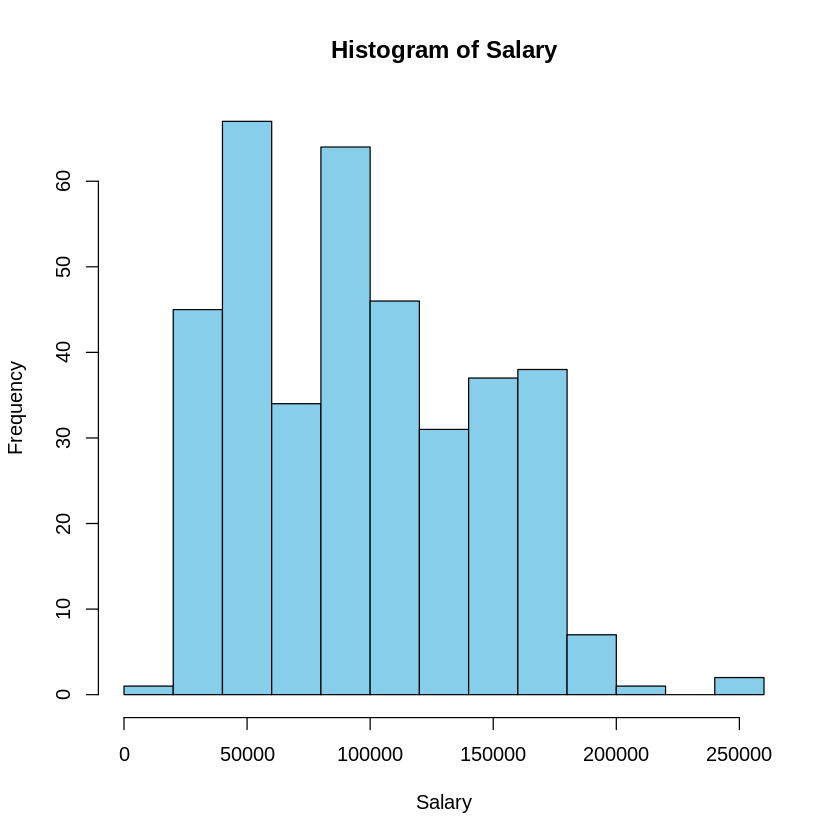

In [ ]:
# Histogram - salary
hist(data_new$salary,
     main = "Histogram of Salary",
     xlab = "Salary",
     col = "skyblue",
     border = "black")

In [ ]:
# Compute the Kurtosis for each numberic variable

# install the package named moments form the CRAN repository
install.packages("moments", repos = "https://cloud.r-project.org")

# Loads the moments pakage into your R session
library(moments)

# Select all numeric columns in the dataset and calculate the kurtosis for each one
sapply(data_new[, sapply(data_new, is.numeric)], kurtosis)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



age experience     salary 
  1.978738   1.951452   2.254368

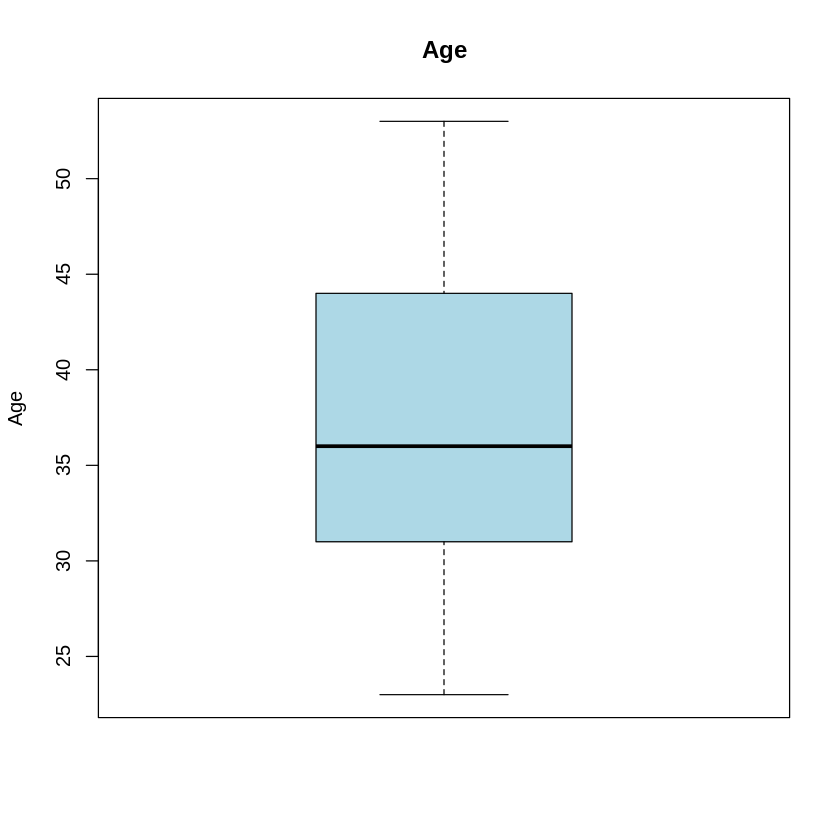

In [ ]:
# Check for outliers (boxplot of numeric variables also form part of the UNIVARIATE Analysis )
# Boxplots - age
boxplot(data_new$age,
        main = "Age",
        ylab = "Age",
        col = "lightblue")

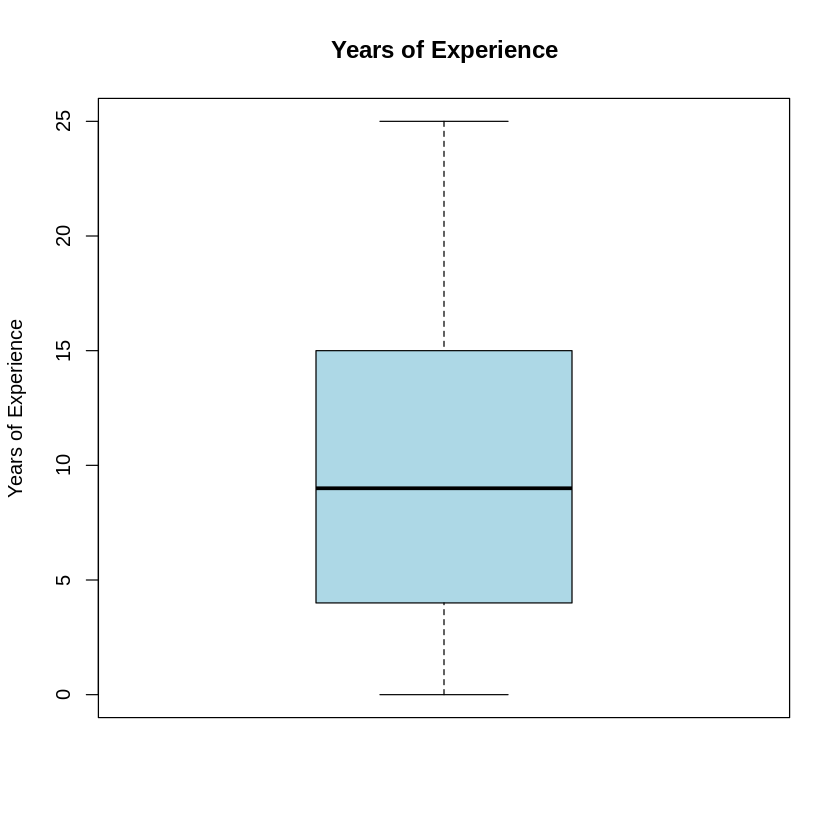

In [ ]:
# Boxplots - years of experience
boxplot(data_new$experience,
        main = "Years of Experience",
        ylab = "Years of Experience",
        col = "lightblue")

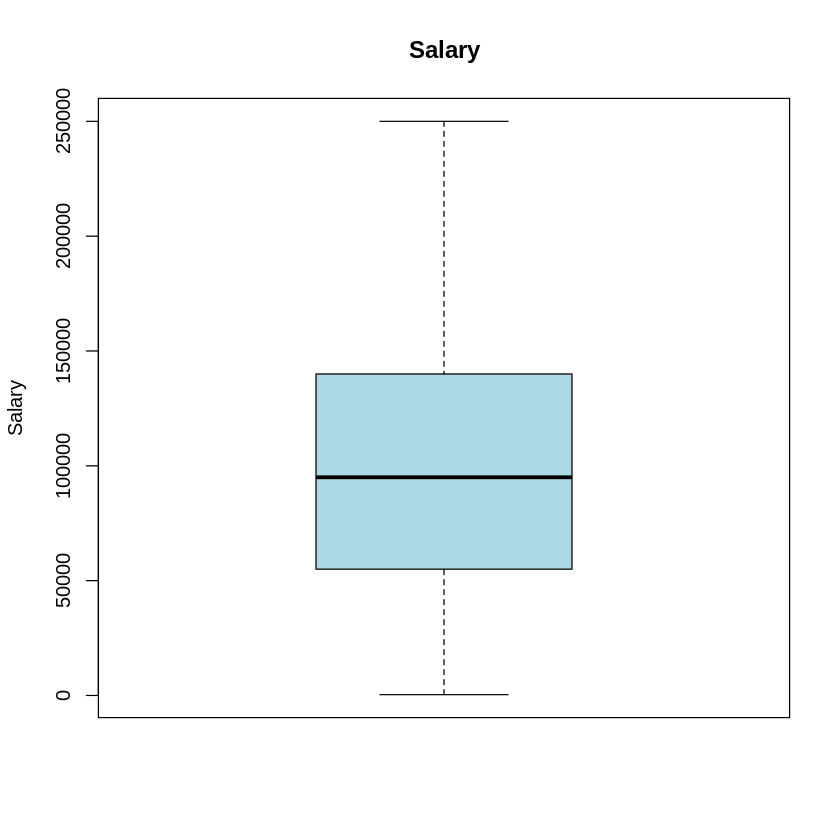

In [ ]:
# Boxplots - salary
boxplot(data_new$salary,
        main = "Salary",
        ylab = "Salary",
        col = "lightblue")

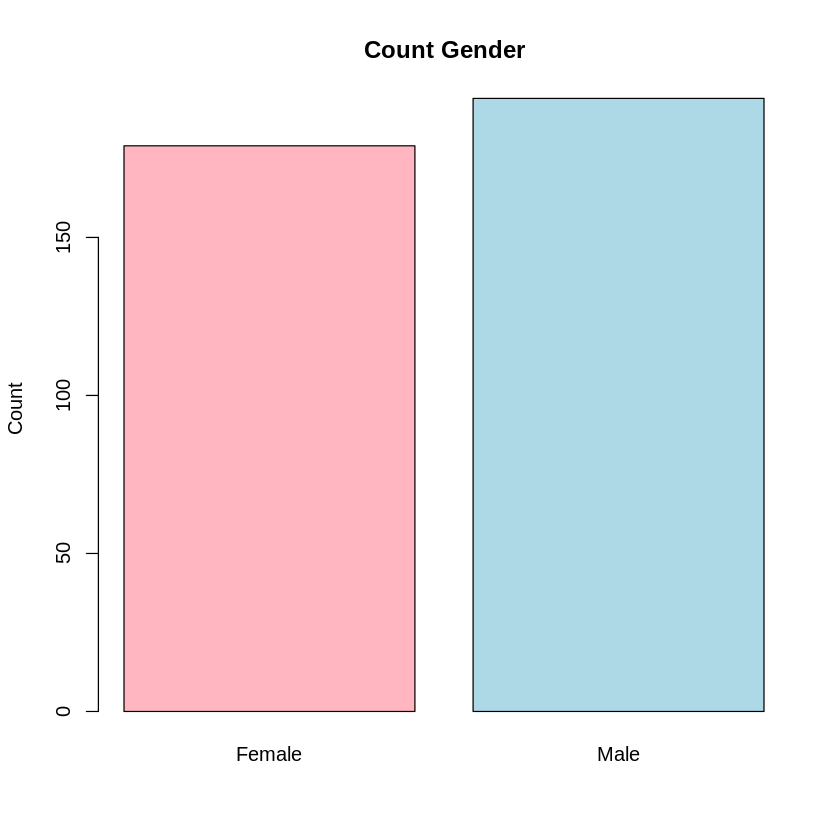

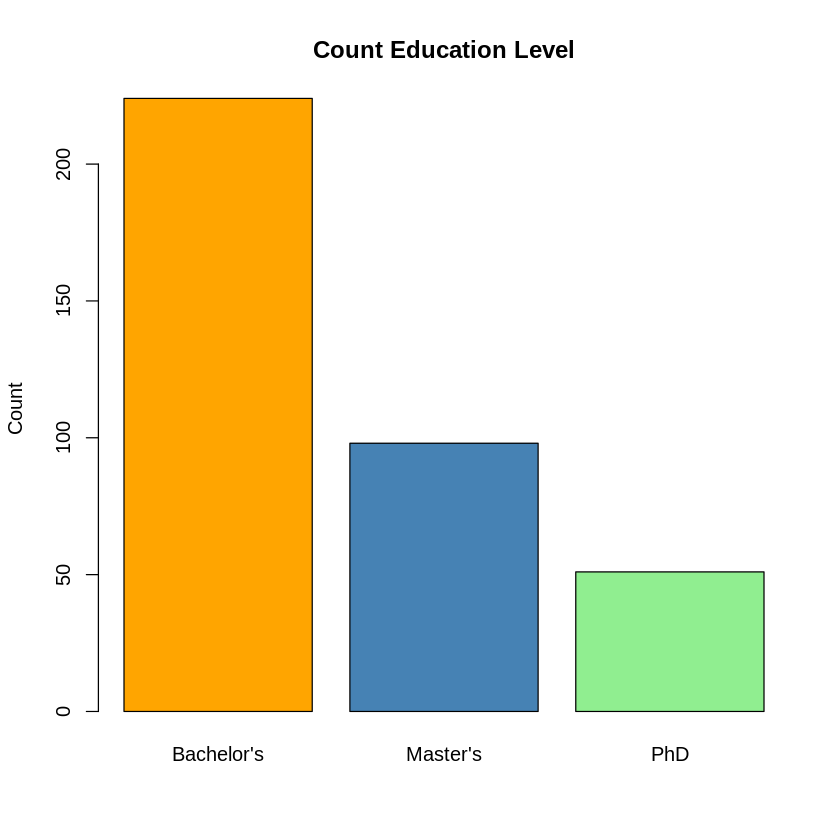


                Director of Marketing                Director of Operations 
                                   12                                    11 
              Senior Business Analyst              Senior Marketing Analyst 
                                   10                                     9 
             Senior Marketing Manager               Junior Business Analyst 
                                    9                                     8 
Junior Business Development Associate              Junior Financial Analyst 
                                    7                                     7 
                Senior Data Scientist              Senior Financial Analyst 
                                    7                                     7 

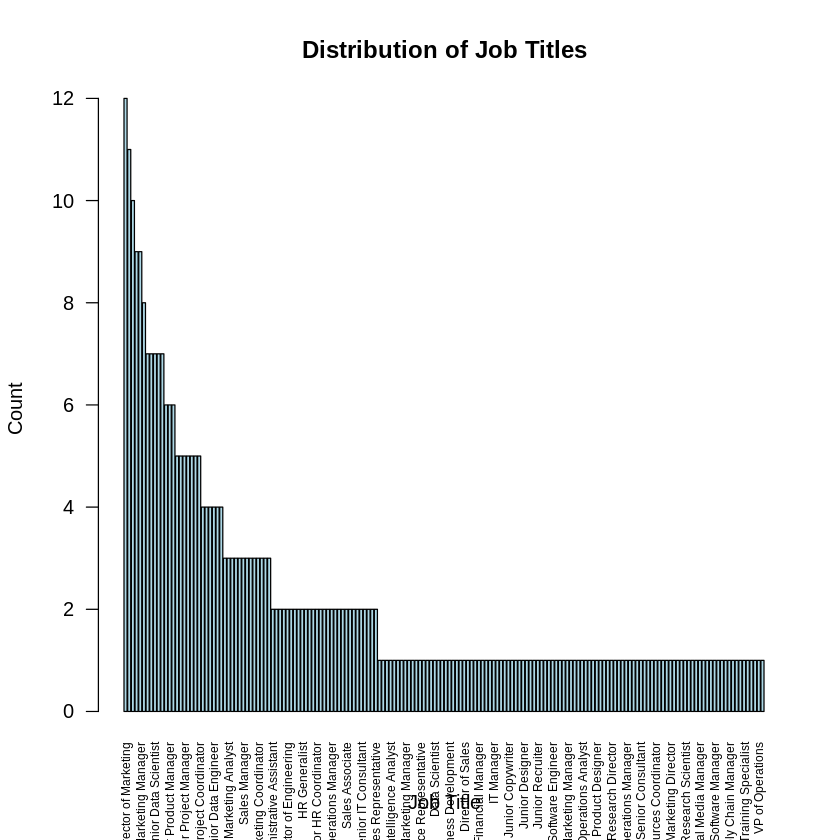

In [ ]:
# Barchart - gender
barplot(table(data_new$gender),
        main = "Count Gender",
        col = c("lightpink", "lightblue"),
        ylab = "Count")

# TO DO - create a barplot of each categorical variable
# Barchart - Education Level
barplot(table(data_new$education),
        main = "Count Education Level",
        col = c("orange", "steelblue", "lightgreen"),
        ylab = "Count")

#There are a large number of job title which will be hard to plot on a barchart so that it is readable try something like this!
job_count <- table(data_new$job)
job_count <- sort(job_count, decreasing = TRUE)  # sort by frequency

barplot(job_count,
        main = "Distribution of Job Titles",
        xlab = "Job Title",
        ylab = "Count",
        las = 2,            # make labels vertical for readability
        col = "lightblue",
        cex.names = 0.6)    # shrink label text if many categories

# Show top 10
head(job_count, 10)

# **BIVARIATE ANALYSIS**

**Scatter plots - You don't need to complete all three steps below for scatter plot - choose one approach (1, 2, or 3)**

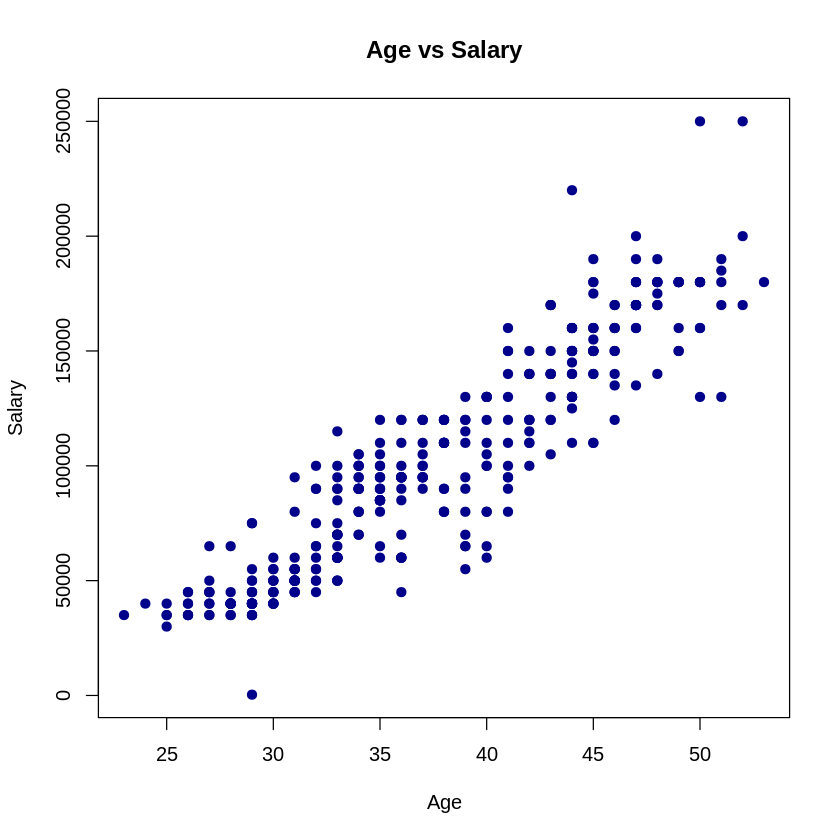

In [ ]:
# Scatter plots for numeric variables (approach 1)

#Scatter plot of age vs salary
plot(data_new$age, data_new$salary,
     main = "Age vs Salary",
     xlab = "Age",
     ylab = "Salary",
     pch = 19, col = "darkblue")

#TO DO - create a scatter plot for each pair of numeric variables

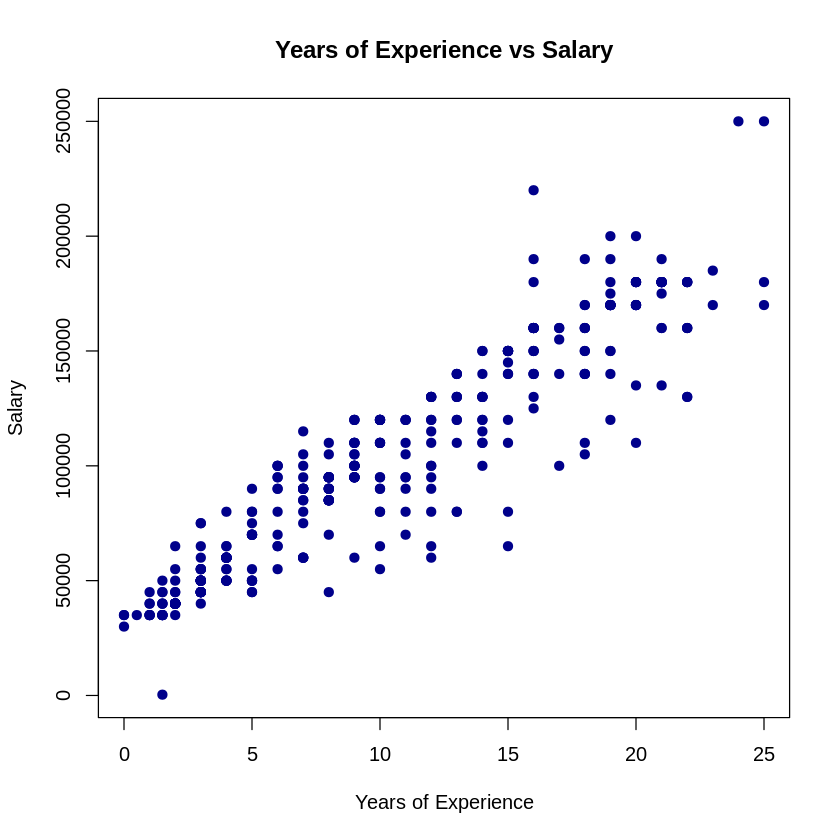

In [ ]:
#Scatter plot of years of experience vs salary
plot(data_new$experience, data_new$salary,
     main = "Years of Experience vs Salary",
     xlab = "Years of Experience",
     ylab = "Salary",
     pch = 19, col = "darkblue")

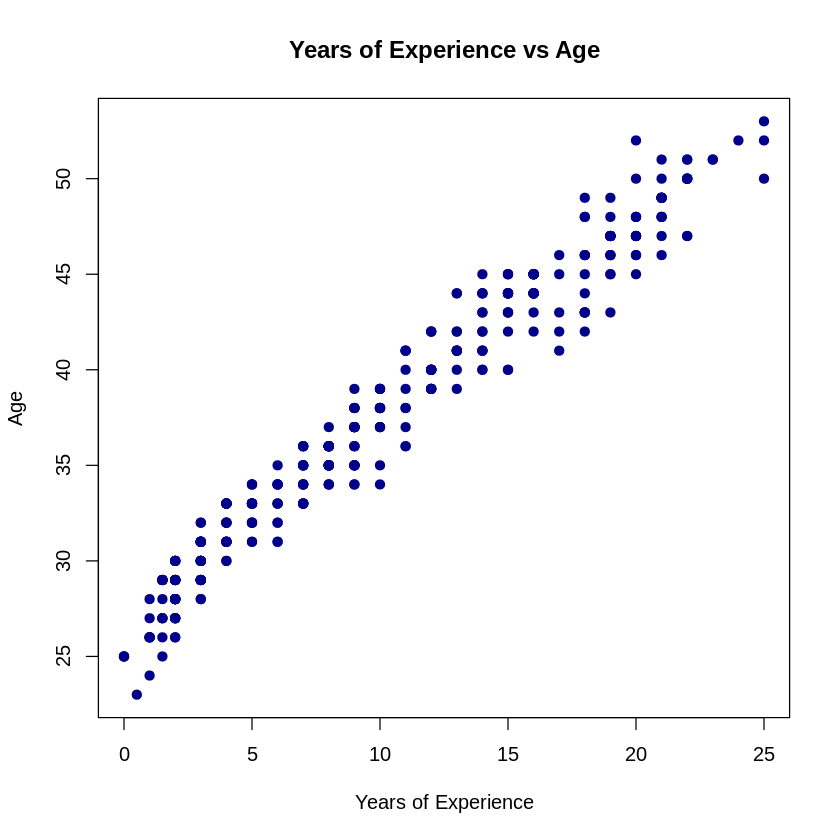

In [ ]:
#Scatter plot of years of experience vs age
plot(data_new$experience, data_new$age,
     main = "Years of Experience vs Age",
     xlab = "Years of Experience",
     ylab = "Age",
     pch = 19, col = "darkblue")

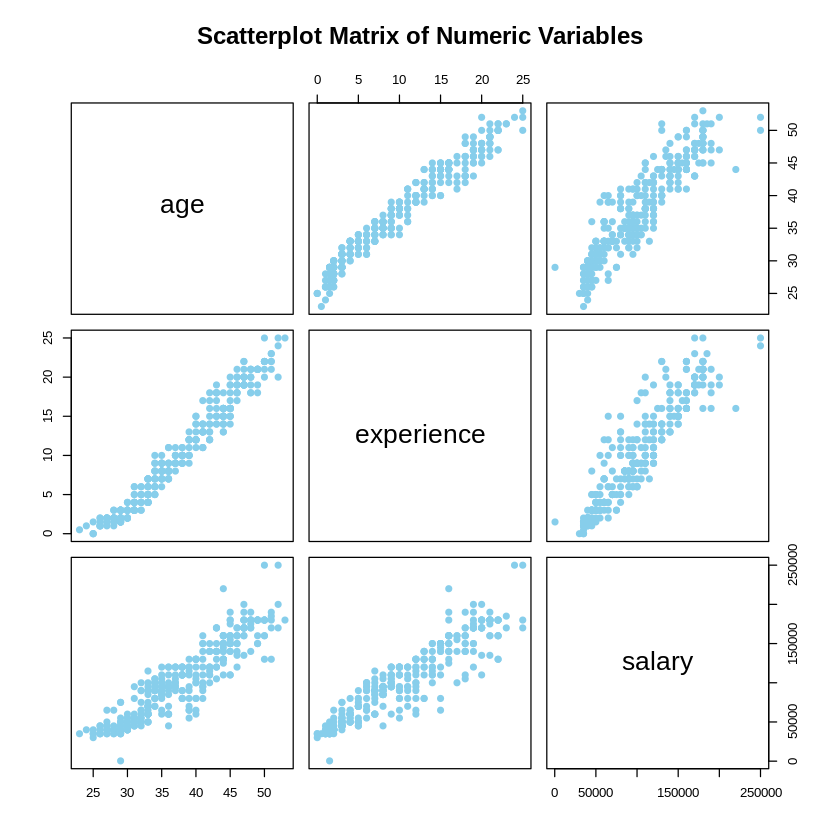

In [ ]:
# Scatter plots for numeric variables (approach 2)

# In the previous step we created individual scatter plot for each pair of numeric variables
# In this step you can create a scatter matrix using the numeric variables (eeach pair completed for you!)

# select only numeric columns
numeric_vars <- sapply(data_new, is.numeric)

# create scatterplot matrix
pairs(data_new[, numeric_vars],
      main = "Scatterplot Matrix of Numeric Variables",
      col = "skyblue",
      pch = 19)

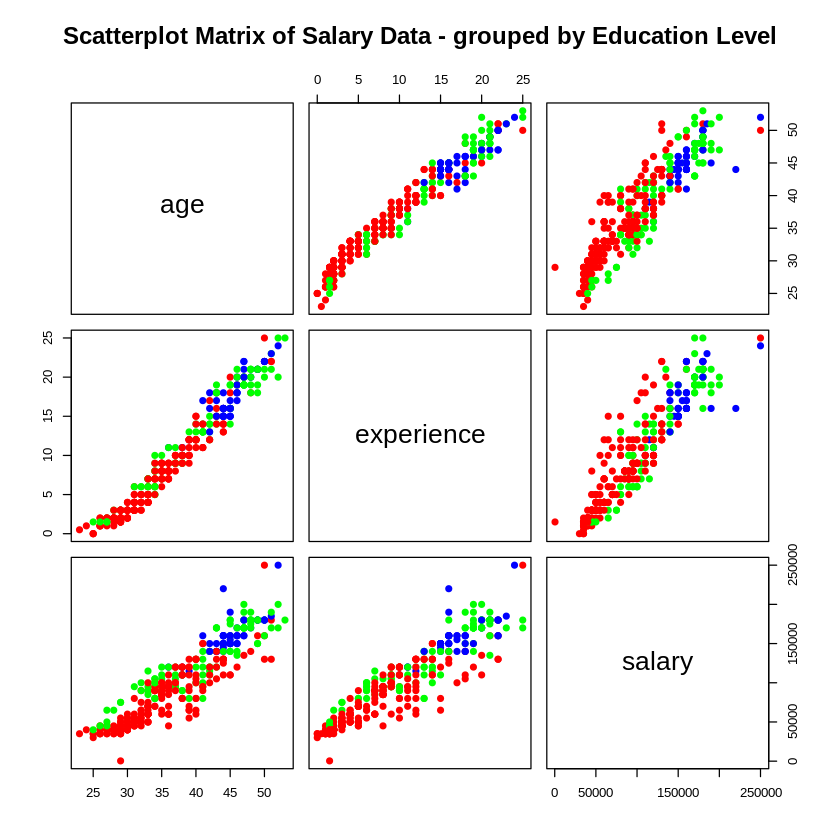

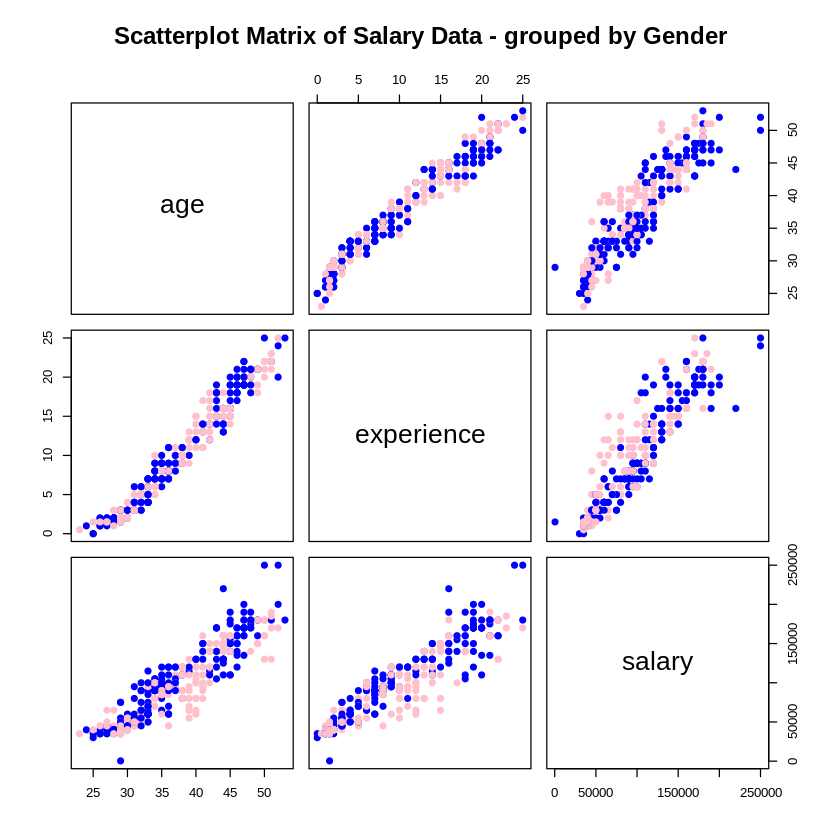

In [ ]:
# Scatter plots for numeric variables (approach 3)

# Assign colors to species
education_colors <- c("Bachelor's" = "red", "Master's" = "green", "PhD" = "blue")

# Create scatterplot matrix (pairs plot)
pairs(data_new[, numeric_vars],
      main = "Scatterplot Matrix of Salary Data - grouped by Education Level",
      pch = 19,
      col = education_colors[data_new$education])

# TO Do - this overlays 'education' - what about the other categorical variables?

# Assign colors to sex
gender_colors <- c("FEMALE" = "pink", "MALE" = "blue")

# Create scatterplot matrix (pairs plot)
pairs(data_new[, numeric_vars],
      main = "Scatterplot Matrix of Salary Data - grouped by Gender",
      pch = 19,
      col = gender_colors[data_new$gender])

In [ ]:
# Creates a data frame of just numeric columns
numeric_data <- data_new[, sapply(data_new, is.numeric)]

# computes the correlation matrix. 'use = "pairwise.complete.obs"'ignores missing vlaues when calculating correlation
cor_mat <- cor(numeric_data, use = "pairwise.complete.obs")

# Display the correlation matrix
print(cor_mat)

                 age experience    salary
age        1.0000000  0.9791281 0.9223352
experience 0.9791281  1.0000000 0.9303377
salary     0.9223352  0.9303377 1.0000000


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



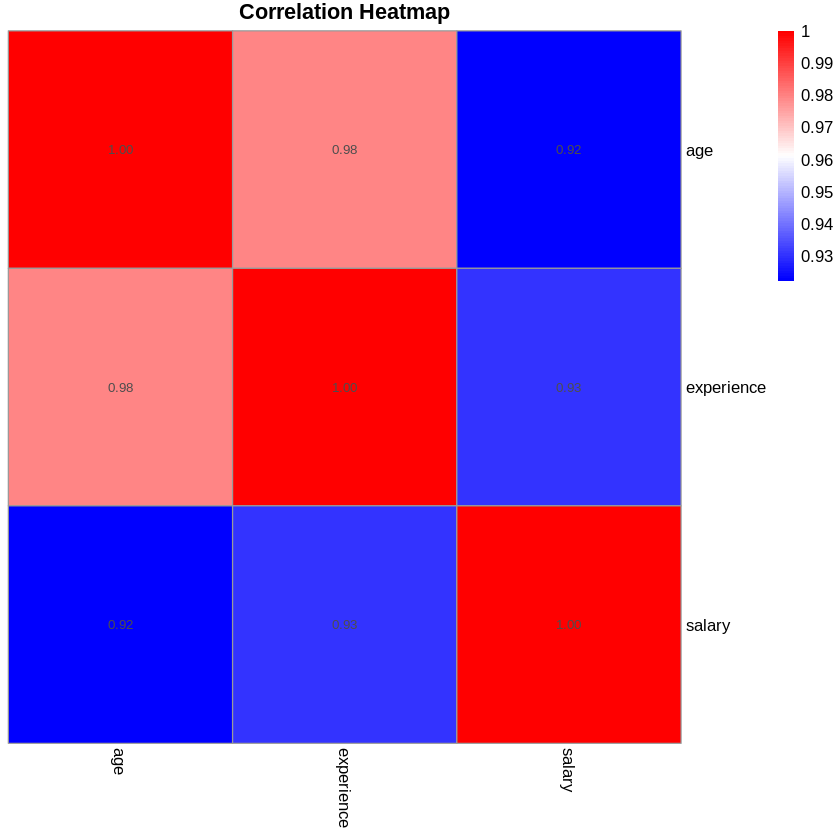

In [ ]:
# Install and Load the required package
install.packages("pheatmap")
# Used for creating heatmaps
library(pheatmap)

# Create a correlation heatmap, diable clustering lines to keep the original order of attributes
pheatmap(cor_mat,
        cluster_rows = FALSE,
         cluster_cols = FALSE,
         display_numbers = TRUE, number_format = "%.2f",
         color = colorRampPalette(c("blue","white","red"))(100),
         clustering_method = "complete", legend = TRUE,
         main = "Correlation Heatmap")

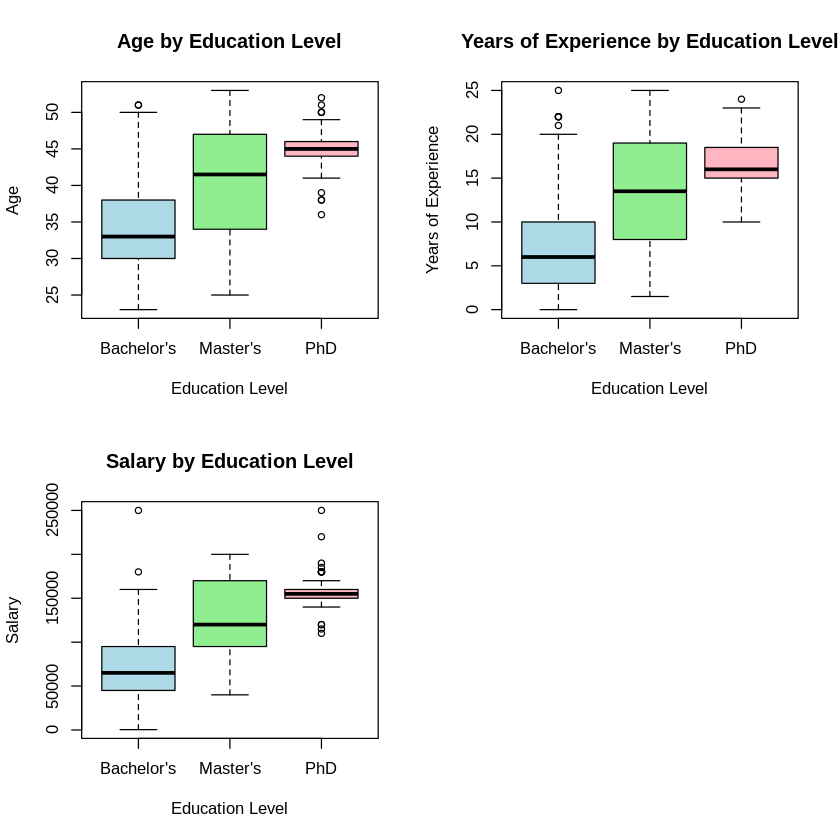

In [ ]:
# Boxplots - BIVARIATE Analysis 1 categorical variable + 1 numerical variable

# Set up a 2x2 plotting area
par(mfrow = c(2, 2))

# Boxplots for each numeric variable grouped by education
boxplot(age ~ education, data_new,
        main = "Age by Education Level",
        xlab = "Education Level", ylab = "Age",
        col = c("lightblue", "lightgreen", "lightpink"))

boxplot(experience ~ education, data_new,
        main = "Years of Experience by Education Level",
        xlab = "Education Level", ylab = "Years of Experience",
        col = c("lightblue", "lightgreen", "lightpink"))

boxplot(salary ~ education, data_new,
        main = "Salary by Education Level",
        xlab = "Education Level", ylab = "Salary",
        col = c("lightblue", "lightgreen", "lightpink"))

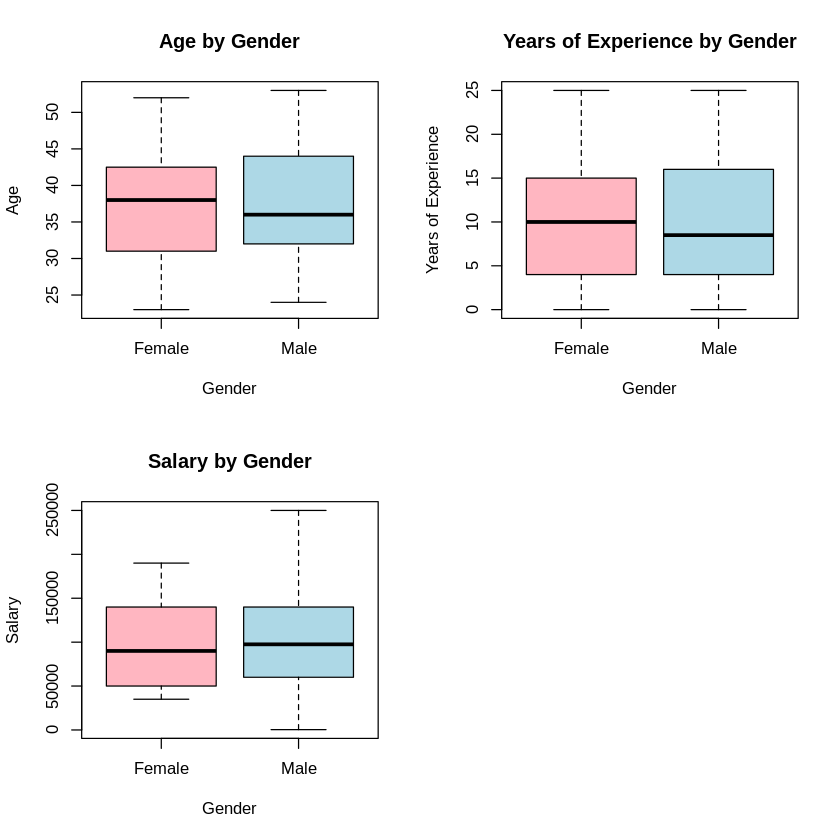

In [ ]:
# Set up a 2x2 plotting area
par(mfrow = c(2, 2))

# Boxplots for each numeric variable grouped by gender
boxplot(age ~ gender, data_new,
        main = "Age by Gender",
        xlab = "Gender", ylab = "Age",
        col = c("lightpink", "lightblue"))

boxplot(experience ~ gender, data_new,
        main = "Years of Experience by Gender",
        xlab = "Gender", ylab = "Years of Experience",
        col = c("lightpink", "lightblue"))

boxplot(salary ~ gender, data_new,
        main = "Salary by Gender",
        xlab = "Gender", ylab = "Salary",
        col = c("lightpink", "lightblue"))

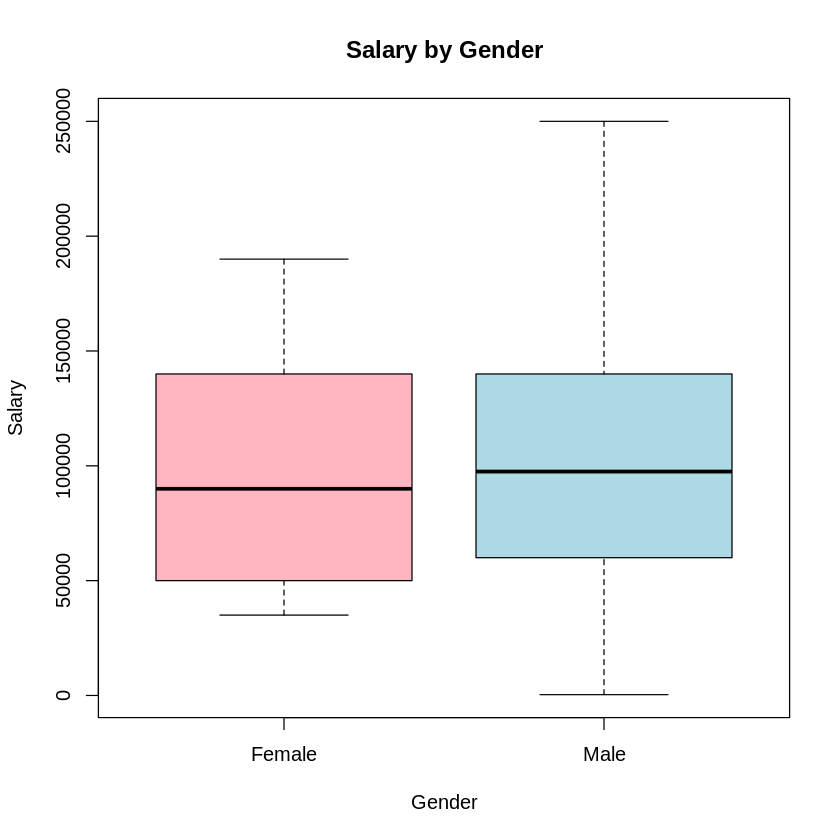

In [ ]:
# Boxplot (1 numeric + 1 categorical continued)

# Salary and Gender
boxplot(salary ~ gender, data_new,
        main = "Salary by Gender",
        xlab = "Gender", ylab = "Salary",
        col = c("lightpink", "lightblue"))

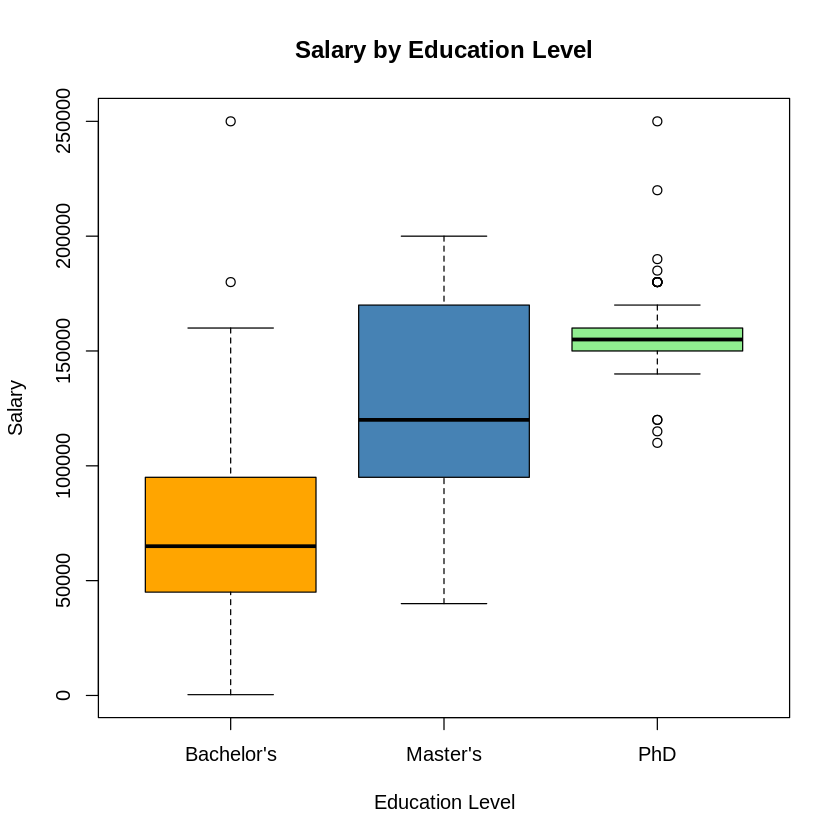

In [ ]:
# Boxplot (1 numeric + 1 categorical continued)

# Salary and Education Level
boxplot(salary ~ education, data_new,
        main = "Salary by Education Level",
        xlab = "Education Level", ylab = "Salary",
        col = c("orange", "steelblue", "lightgreen"))

        
         Bachelor's Master's PhD
  Female        103       50  26
  Male          121       48  25



	Pearson's Chi-squared test

data:  table_result
X-squared = 0.9051, df = 2, p-value = 0.636


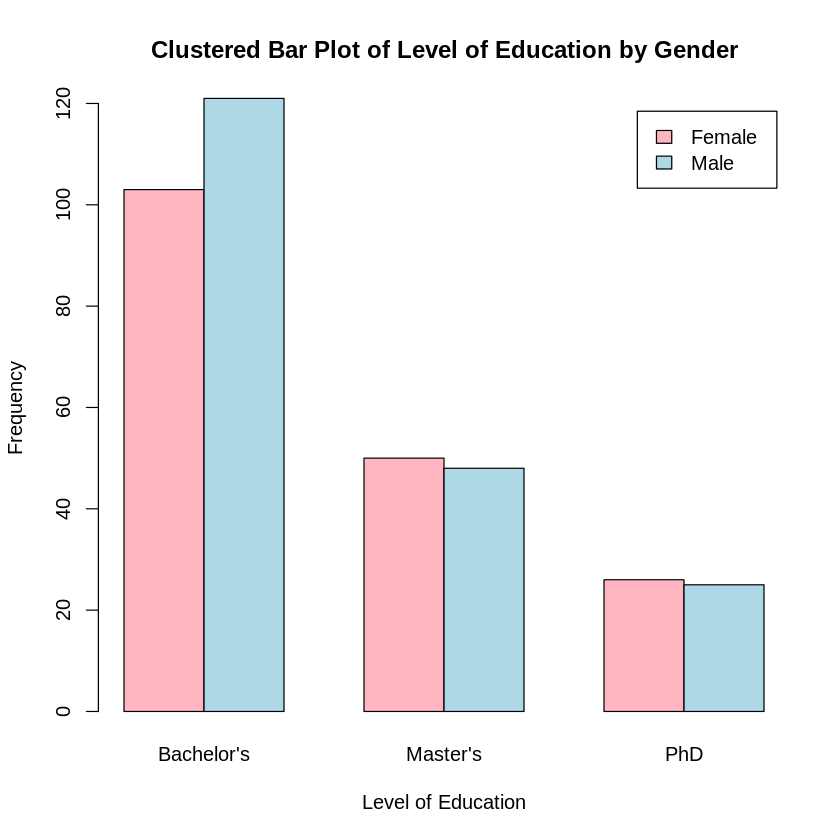

In [ ]:
# Cross-tabulation & Clutered Bar chart BIVARIATE Analysis relationship between 2 categorical variables

# Create a cross-tabulation
table_result <- table(data_new$gender, data_new$education)
print(table_result)

# Create clustered bar plot
barplot(table_result,
        beside = TRUE,                # side-by-side bars (clustered)
        col = c("lightpink", "lightblue"),
        legend = rownames(table_result),
        main = "Clustered Bar Plot of Level of Education by Gender",
        xlab = "Level of Education",
        ylab = "Frequency")

# Perform Chi-square test to determine if there is significant association between the two cateogorical variable
chisq.test(table_result)


In [ ]:
# There are a large number of job title and so it may not be easy to see for example on a clustered barchart the breakdown for gender. so you could try the following:
# look at the proportion of jobs for Male and Female

# Create table for job and gender
tab <- table(data_new$job, data_new$gender)

# Convert to proportions by row (per job)
prop_tab <- prop.table(tab, margin = 1)

# Mostly male jobs
male_jobs <- rownames(prop_tab)[prop_tab[, "Male"] > 0.6]
# Mostly female jobs
female_jobs <- rownames(prop_tab)[prop_tab[, "Female"] > 0.6]

cat("Mostly male jobs:\n"); print(male_jobs)
cat("\nMostly female jobs:\n"); print(female_jobs)

Mostly male jobs:
 [1] "Account Manager"                     "Business Development Manager"       
 [3] "Business Intelligence Analyst"       "CEO"                                
 [5] "Chief Data Officer"                  "Chief Technology Officer"           
 [7] "Customer Service Rep"                "Customer Success Manager"           
 [9] "Data Scientist"                      "Director"                           
[11] "Director of Business Development"    "Director of Engineering"            
[13] "Director of Marketing"               "Director of Product Management"     
[15] "Director of Sales"                   "Financial Analyst"                  
[17] "Financial Manager"                   "Help Desk Analyst"                  
[19] "IT Manager"                          "IT Support"                         
[21] "IT Support Specialist"               "Junior Accountant"                  
[23] "Junior Advertising Coordinator"      "Junior Business Analyst"            
[25] "Juni

# **Adding Data Visualisation Elements with ggplot**

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



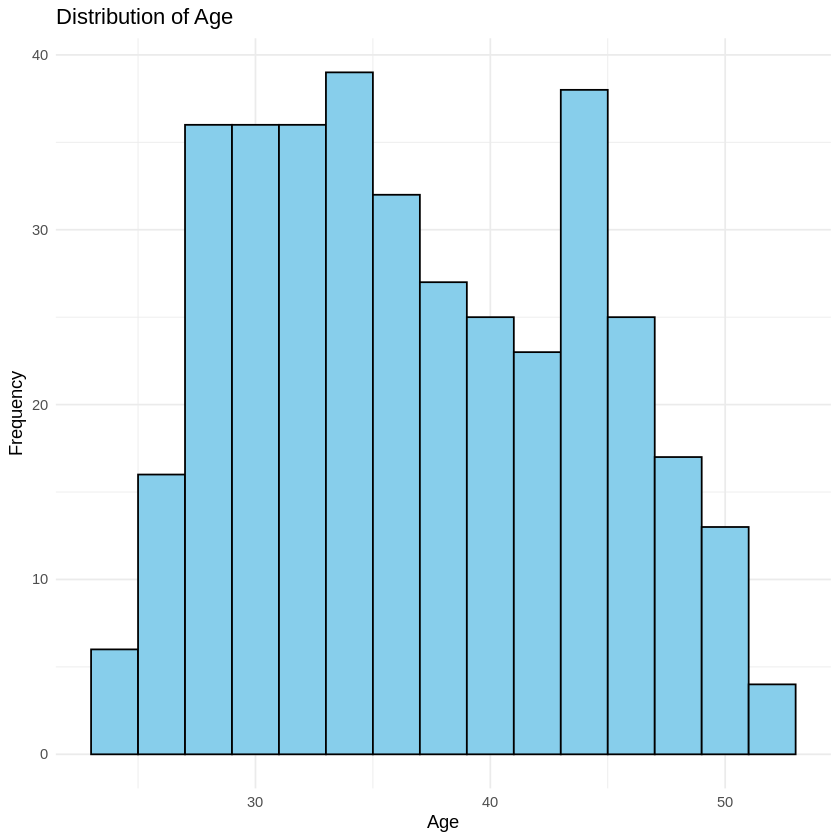

In [ ]:
# install the ggplot2 package from CRAN - only need to do this once
install.packages("ggplot2")

# Load the ggplot2 package for advanced data visualisation
library(ggplot2)

# Create a histogram to explore the distribution of age
# Define dataset and aesthetic mapping  - x-axis variable
ggplot(data_new, aes(x = age)) +

 # Add histogram geometry
  geom_histogram(
    binwidth = 2,              # width of each bin (can be adjusted)
    fill = "skyblue",          # bar fill color
    color = "black"            # border color
  ) +

  # Add descriptive labels and title - Main title for the plot,  X-axis label with measurement units,  Y-axis label indicating count of observations
  labs(
    title = "Distribution of Age",
    x = "Age",
    y = "Frequency"
  ) +

  # Apply a clean, minimal theme for better readability - removes unnecessary gridlines and background
  theme_minimal()

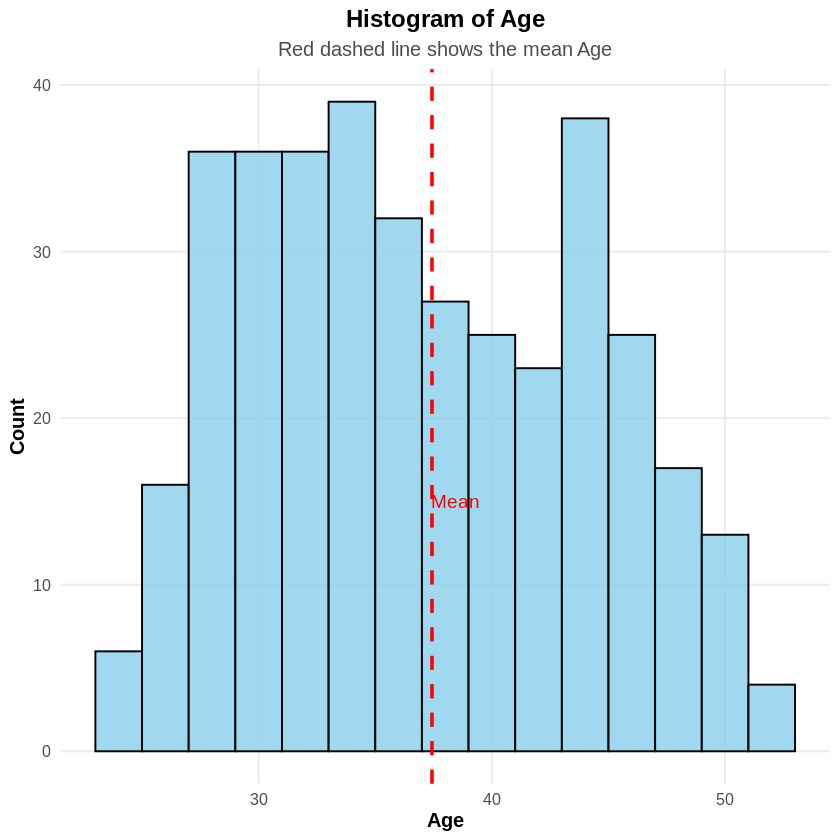

In [ ]:
# Load the ggplot2 library for data visualisation

# Create a histogram of age with visual design elements aesthetic mapping for the x-axis variable
ggplot(data_new, aes(x = age)) +

# Add the histogram layer to show the distribution, setting the bin width, fill colour, outline for the bars and transparency to make the bars slightly see through
  geom_histogram(
    binwidth = 2,
    fill = "skyblue",
    color = "black",
    alpha = 0.8
  ) +

   # Add a vertical dashed line to show the mean age
  geom_vline(
    # Draw line at mean value adding line colour , line type and line width
    aes(xintercept = mean(age, na.rm = TRUE)),
    color = "red",
    linetype = "dashed",
    linewidth = 1
  ) +

  # Annotate the plot with a text label indicating the mean, position slightly to the right of the mean line, add the text to display with colour and size of the font
  annotate("text",
           x = mean(data_new$age) + 1,
           y = 15,
           label = "Mean",
           color = "red",
           size = 4) +

  # Add descriptive titles, subtitle, and axis labels
  labs(
    title = "Histogram of Age",
    subtitle = "Red dashed line shows the mean Age",
    x = "Age",
    y = "Count",
  ) +

  # Apply a minimal theme for a clean, professional appearance including font size (base_size) for text. Center and bold titles.
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5, color = "gray30"),
    axis.title = element_text(face = "bold"),
    panel.grid.minor = element_blank()
  )


| Element              | Purpose                          | Example                                            |
| -------------------- | -------------------------------- | -------------------------------------------------- |
| **Title & subtitle** | Give clear context               | `"Histogram of Age "`             |
| **Color & fill**     | Make the chart visually distinct | `fill = "skyblue"`                                 |
| **Borders**          | Improve contrast between bins    | `color = "black"`                                  |
| **Reference line**   | Highlight key statistic          | `geom_vline(xintercept = mean(...))`               |
| **Annotation**       | Label the reference line         | `annotate("text", label = "Mean")`                 |
| **Theme**            | Improve readability              | `theme_minimal()` removes clutter                  |


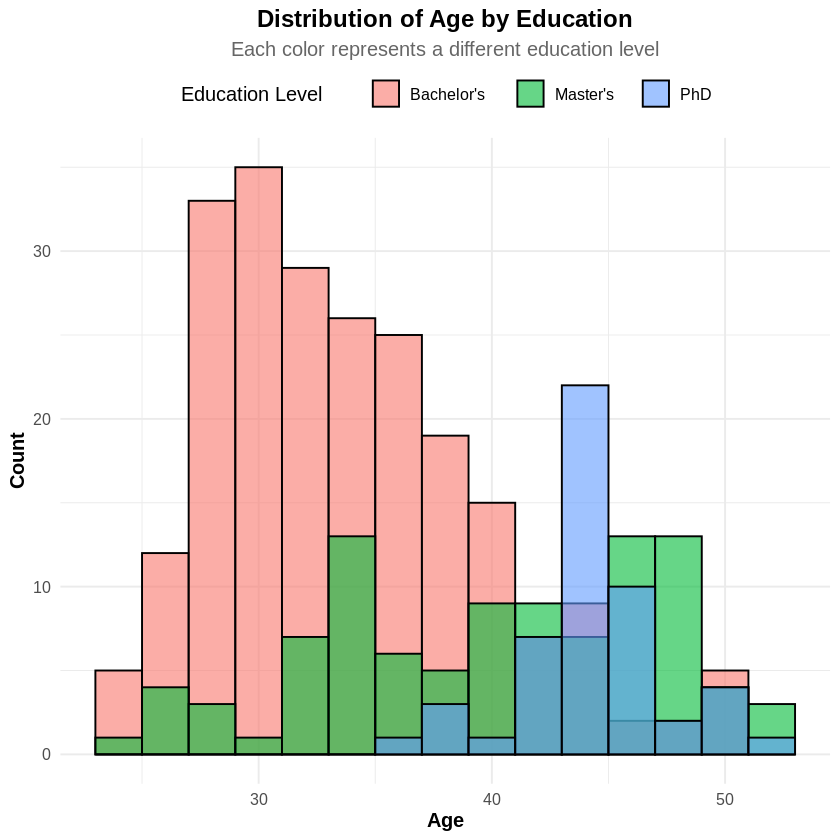

In [ ]:
# Load ggplot2 library for data visualisation
library(ggplot2)

# Create a grouped histogram to compare age distributions by education level -  x-axis variable, and fill color grouping
ggplot(data_new, aes(x = age, fill = education)) +

 # Add histogram layer setting the bin width, fill colour, outline for the bars. position = 'identity' allows for the overlay of the histograms according to grouping
  geom_histogram(
    binwidth = 2,
    color = "black",
    alpha = 0.6,
    position = "identity"
  ) +

  # Add descriptive labels and legend title
  labs(
    title = "Distribution of Age by Education",
    subtitle = "Each color represents a different education level",
    x = "Age",
    y = "Count",
    fill = "Education Level",
  ) +

  # Apply a minimal theme for a clean and professional appearance including font size (base_size) for text. Center and bold titles.
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(hjust = 0.5, color = "gray40"),
    axis.title = element_text(face = "bold"),
    legend.position = "top"
  )


| Argument / Function     | Purpose                                                      |
| ----------------------- | ------------------------------------------------------------ |
| `fill = education`        | Assigns color by education level                             |
| `alpha = 0.6`           | Makes bars semi-transparent so overlapping areas are visible |
| `position = "identity"` | Overlays histograms instead of stacking                      |
| `labs()`                | Adds title, subtitle, axis labels, legend title, and caption |
| `theme_minimal()`       | Clean, modern background with minimal gridlines              |